# 02 — granja

**Purpose:** Reproduce the manuscript figure panels from already generated numerical tables. This notebook does not fit scCHART or regenerate the simulations. The computational pipelines are in `scripts/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work whether launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results").is_dir(), "Open from scCHART_analysis/ or notebooks/"
FIG_ROOT = ROOT / "figures"
MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
EPI, JAC = "#C0632B", "#8C8C8C"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def label(ax, s, **kw):
    """Plain left-aligned label above an axes."""
    ax.set_title(s, loc=kw.pop("loc", "left"), fontsize=kw.pop("fontsize", FS_ANN), color=INK, pad=kw.pop("pad", 2), **kw)

def halo(width=1.4):
    import matplotlib.patheffects as pe
    return [pe.withStroke(linewidth=width, foreground="white")]

def fmt_p(p, sym="P"):
    """P = 0.56, P = 0.015, P = 4.7 × 10⁻⁴ (mathtext superscript), as printed on the frozen figures."""
    import numpy as np
    if p >= 0.01:
        s = f"{p:.2f}" if p >= 0.1 else f"{p:#.2g}"
        return f"{sym} = {s}"
    e = int(np.floor(np.log10(p))); m = p / 10 ** e
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f"{sym} = {m:.1f} × 10$^{{{e}}}$"

def short(g: str) -> str:
    """Granja population id -> display name ('01_HSC' -> 'HSC'; unannotated clusters -> 'Unk 13')."""
    return "Unk " + g.split("_")[0] if g.endswith("Unk") else g.split("_", 1)[1]

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# Manuscript source names -> directories in the public analysis repository.
RESULT_DIRS = {
    "01_synthetic_benchmarks": "01_benchmarks",
    "02_hematopoiesis": "02_granja",
    "03_CATLAS_programmes": "03_catlas",
    "04_xenograft_HSC": "04_hsc",
    "05_method_comparisons": "05_method_comparisons",
}

def result_path(rel):
    parts = Path(rel).parts
    if len(parts) >= 3 and parts[1] == "results":
        return ROOT / "results" / RESULT_DIRS.get(parts[0], parts[0]) / Path(*parts[2:])
    return ROOT / rel

def read(rel, cols=None, n_rows=None):
    path = result_path(rel)
    df = pd.read_csv(path, sep="\t")
    if cols:
        missing = set(cols) - set(df.columns)
        assert not missing, f"{path}: missing {sorted(missing)}"
    if n_rows is not None:
        assert len(df) == n_rows, f"{path}: {len(df)} rows, expected {n_rows}"
    return df

def printed(panel, quantity, exact, fmt, source, flag=False):
    # Format a value read from a result table; no frozen-manuscript comparisons.
    return fmt(exact) if callable(fmt) else (format(exact, fmt) if fmt else str(exact))

OUTPUT_DIR = FIG_ROOT / "02_granja"  # notebook section sets this explicitly.

def save(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for ext, opts in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(path, **opts)
        print(path.relative_to(ROOT))

def build(name, size_mm, panels):
    cv = Canvas(*size_mm)
    for letter, x, y, draw in panels:
        region = Region(cv, x, y)
        draw(region)
        if letter:
            region.letter(letter)
    save(cv.fig, name)
    return cv

fs = SimpleNamespace(**{k: globals()[k] for k in (
    "apply_style", "Canvas", "Region", "label", "halo", "fmt_p", "short", "blank",
    "read", "save", "build", "printed", "ROOT", "STRUCT", "STRUCT_L", "PROG", "PROG_L",
    "EPI", "JAC", "INK", "MUTED", "GUIDE", "NEUTRAL_L", "FS_LETTER", "FS_LABEL",
    "FS_TICK", "FS_ANN", "FS_SMALL", "FS_MIN")})
apply_style()


## Figure 3

**Scientific question.** Do the structural and programme heterogeneity axes identify the same populations, and do immature and mature hematopoietic states differ? The display uses matched-depth scores and the previously computed HSPC contrasts and cross-dataset results. Figures are assembled from validated tables, not recalculated in this notebook.

In [2]:
OUTPUT_DIR = ROOT / "figures" / "02_granja"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

"""Biological categories of the 26 Granja populations used for colouring Figure 3 and Figure S4.

Same definition as the HSPC versus mature analysis in 02_hematopoiesis/notebooks/02_hematopoiesis.ipynb (manuscript
Methods): 9 HSPC populations (5 strict: HSC, CMP.LMPP, CLP.1, CLP.2, GMP; 4 committed precursors: Early.Eryth,
Early.Baso, GMP.Neut, Pre.B), 14 mature populations (Late.Eryth flagged ambiguous), 3 unannotated clusters excluded.
Colours and markers are those of the frozen figures (palette disjoint from the structural blue / programme green).
"""


import pandas as pd
from matplotlib.lines import Line2D

STRICT = ["01_HSC", "05_CMP.LMPP", "06_CLP.1", "15_CLP.2", "07_GMP"]
COMMITTED = ["02_Early.Eryth", "04_Early.Baso", "08_GMP.Neut", "16_Pre.B"]
UNANNOTATED = ["13_Unk", "14_Unk", "26_Unk"]
AMBIGUOUS = ["03_Late.Eryth"]

HSPC, MATURE, UNK = "HSPC", "mature", "unannotated"
HSPC_C, MAT_C, UNK_C = "#B0306F", "#4D4D4D", "#BDBDBD"
STYLE = {HSPC: dict(fc=HSPC_C, ec=HSPC_C, m="o", lab="HSPCs", map=HSPC_C),
         MATURE: dict(fc="white", ec=MAT_C, m="o", lab="Mature", map="#8A8A8A"),
         UNK: dict(fc=UNK_C, ec="#8F8F8F", m="s", lab="Unannotated", map="#D9D9D9")}


def classify(populations) -> pd.Series:
    s = pd.Series(MATURE, index=list(populations))
    s[s.index.isin(STRICT + COMMITTED)] = HSPC
    s[s.index.isin(UNANNOTATED)] = UNK
    assert (s == HSPC).sum() == 9 and (s == MATURE).sum() == 14 and (s == UNK).sum() == 3
    return s


def handles(classes: pd.Series, counts=True, keys=(HSPC, MATURE, UNK)):
    n = classes.value_counts()
    return [Line2D([], [], ls="", marker=STYLE[k]["m"], ms=3.2, mfc=STYLE[k]["fc"], mec=STYLE[k]["ec"], mew=0.6,
                   label=f"{STYLE[k]['lab']} ({n[k]})" if counts else STYLE[k]["lab"]) for k in keys]

gc = SimpleNamespace(**{k: globals()[k] for k in (
    "STRICT", "COMMITTED", "UNANNOTATED", "AMBIGUOUS", "HSPC", "MATURE", "UNK",
    "HSPC_C", "MAT_C", "UNK_C", "STYLE", "classify", "handles")})

import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
SIZE = (183, 222)
PANELS = {"a": (0, 0, 183, 64), "b": (0, 68, 118, 86), "c": (120, 68, 63, 66), "d": (0, 158, 84, 64),
          "e": (86, 158, 97, 64)}
PANEL_REGIONS = PANELS
R2, R3 = "02_hematopoiesis/results/", "03_CATLAS_programmes/results/"
cells = fs.read(R2 + "granja_cells.tsv.gz", ["population", "umap1", "umap2", "scchart_structural_d", "scchart_programme_d"],
                35038)
pop = fs.read(R2 + "granja_population_summary.tsv",
              ["population", "Delta_G_Dstar", "Delta_G_Dstar_sd", "Delta_P_Dstar", "Delta_P_Dstar_sd", "D_star_structural",
               "D_star_programme"], 26).set_index("population")
pop["class"] = gc.classify(pop.index)
cells["class"] = cells.population.map(pop["class"])
tests = fs.read(R2 + "hspc_vs_mature_tests.tsv", ["comparison", "score", "cliffs_delta", "p_exact"])
dadj = fs.read(R2 + "hspc_contrast_by_matching.tsv", ["axis", "condition", "p_HSPC"])
xsum = fs.read(R2 + "crossdataset_summary.tsv", ["score", "primary_spearman_rho", "primary_spearman_p_exact"]).set_index("score")
bu_s = fs.read(R2 + "buenrostro_population_sets_summary.tsv", ["population", "Delta_G_matched", "D_star"]).set_index("population")
gr_s = fs.read(R2 + "granja_population_sets_summary.tsv", ["population", "Delta_G_matched", "D_star"]).set_index("population")
bu_p = fs.read(R3 + "buenrostro_catlas_Bheme_population_summary.tsv", ["population", "Delta_P_Dstar", "D_star"]).set_index("population")
gr_p = fs.read(R3 + "granja_catlas_Bheme_population_summary.tsv", ["population", "Delta_P_Dstar", "D_star"]).set_index("population")
PAIRS = [("HSC", "01_HSC"), ("CMP", "05_CMP.LMPP"), ("GMP", "07_GMP"), ("CLP", "06_CLP.1"), ("MEP", "02_Early.Eryth"),
         ("mono", "11_CD14.Mono.1")]
ORDER = list(pop.sort_values("Delta_G_Dstar", ascending=False).index)

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [3]:
def cat_marker(ax, x, y, g, tr, s=9):
    st = gc.STYLE[pop.loc[g, "class"]]
    ax.scatter([x], [y], s=s, marker=st["m"], facecolors=st["fc"], edgecolors=st["ec"], lw=0.5, transform=tr, clip_on=False)

def row_labels(ax, groups, xoff=-0.07, mk=-0.025):
    tr = ax.get_yaxis_transform()
    for i, g in enumerate(groups):
        hs = pop.loc[g, "class"] == gc.HSPC
        ax.text(xoff, i, short(g), transform=tr, ha="right", va="center", fontsize=FS_SMALL,
                fontweight="bold" if hs else "normal", color=gc.HSPC_C if hs else INK)
        cat_marker(ax, mk, i, g, tr, s=7)

def legend_handles():
    n = pop["class"].value_counts()
    for k, lab in ((gc.HSPC, "HSPC"), (gc.MATURE, "mature"), (gc.UNK, "unannotated")):
        printed("b", f"legend: {lab} populations", int(n[k]), "d", R2 + "granja_population_summary.tsv + granja_classes.py")
    return gc.handles(pop["class"])

### Panel a — Cell-level distributions

In [4]:
def panel_a(P):
    X = [4, 64, 124]

    def umap_ax(x, y, w=54, h=44):
        ax = P.ax(x, y, w, h); fs.blank(ax); ax.set_aspect("equal", "datalim")
        return ax

    ax = umap_ax(X[0], 7)
    ax.scatter(cells.umap1, cells.umap2, s=0.12, c=cells["class"].map({k: v["map"] for k, v in gc.STYLE.items()}),
               lw=0, rasterized=True)
    off = {"CD14.Mono.1": (-1.9, -0.6), "CD14.Mono.2": (1.9, 0.3), "CD4.N1": (1.0, -0.4), "CD8.N": (-0.7, -0.8),
           "CD4.N2": (-1.1, 0.2), "CLP.1": (0.7, -0.1), "CMP.LMPP": (-0.9, 0.3), "Pre.B": (0.5, 0.3)}
    for g, d in cells.groupby("population"):
        if len(d) < 600 or g.endswith("Unk"):
            continue
        n = short(g); dx, dy = off.get(n, (0, 0))
        hs = pop.loc[g, "class"] == gc.HSPC
        ax.text(d.umap1.median() + dx, d.umap2.median() + dy, n, fontsize=FS_MIN, ha="center", va="center",
                color=gc.HSPC_C if hs else INK, fontweight="bold" if hs else "normal", path_effects=fs.halo())
    nc = printed("a", "Granja cells", len(cells), ",d", R2 + "granja_cells.tsv.gz")
    npop = printed("a", "Granja populations", cells.population.nunique(), "d", R2 + "granja_cells.tsv.gz")
    P.text(X[0] + 27, 1.6, f"Granja atlas: {nc} cells, {npop} populations", ha="center", fontsize=FS_ANN,
           fontweight="bold")
    h = [Line2D([], [], ls="", marker="o", ms=3, mfc=v["map"], mec=v["map"], label=v["lab"]) for v in gc.STYLE.values()]
    lg = P.ax(X[0], 54, 54, 6); fs.blank(lg)
    lg.legend(handles=h, loc="upper center", ncol=3, fontsize=FS_SMALL, handletextpad=0.1, columnspacing=0.8,
              borderaxespad=0)
    for x, col, cmap, ttl, cbl, colour in (
            (X[1], "scchart_structural_d", "Blues", "Structural per-cell contribution", "$d_i^{(S)}$ (bits)", STRUCT),
            (X[2], "scchart_programme_d", "Greens", "Programme per-cell contribution", "$d_i^{(P)}$ (bits)", PROG)):
        ax = umap_ax(x, 7)
        vmax = float(np.quantile(cells[col], 0.99))
        sc = ax.scatter(cells.umap1, cells.umap2, s=0.12, c=cells[col], cmap=cmap, norm=Normalize(0, vmax), lw=0,
                        rasterized=True)
        P.text(x + 27, 1.6, ttl, ha="center", fontsize=FS_ANN, fontweight="bold", color=colour)
        cax = P.ax(x + 12, 55, 30, 1.8)
        cb = P.fig.colorbar(sc, cax=cax, orientation="horizontal", extend="max")
        cb.outline.set_visible(False); cb.ax.tick_params(labelsize=FS_SMALL, length=1.5, pad=1)
        cb.set_label(cbl + ", uncalibrated", fontsize=FS_SMALL, labelpad=1)

### Panel b — Population-level rankings

In [5]:
def panel_b(P):
    d = pop.loc[ORDER]
    y = np.arange(len(d))
    a1, a2 = P.ax(33, 12, 36, 62), P.ax(76, 12, 36, 62)
    for ax, col, sd, c, lab in ((a1, "Delta_G_Dstar", "Delta_G_Dstar_sd", STRUCT, "Structural $\\Delta_G$(D*) (bits)"),
                                (a2, "Delta_P_Dstar", "Delta_P_Dstar_sd", PROG, "Programme $\\Delta_G^{(P)}$(D*) (bits)")):
        ax.hlines(y, 0, d[col], color=fs.GUIDE, lw=0.4)
        ax.errorbar(d[col], y, xerr=d[sd].fillna(0), fmt="none", ecolor=c, elinewidth=0.6)
        ax.scatter(d[col], y, s=6, c=c, zorder=3, lw=0)
        ax.set_ylim(len(d) - 0.4, -0.6); ax.set_xlim(0, 0.72)
        ax.set_xlabel(lab, labelpad=6); ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
        ax.spines["bottom"].set_visible(False); ax.spines["top"].set_visible(True)
        ax.set_xticks([0, 0.2, 0.4, 0.6]); ax.set_yticks([])
    row_labels(a1, ORDER, xoff=-0.09, mk=-0.035)
    D = printed("b", "matched depth D* (counts)", float(pop.D_star_structural.iloc[0]), "g", R2 + "granja_population_summary.tsv")
    assert (pop.D_star_structural == pop.D_star_programme).all()
    P.text(4, 77.5, f"Matched depth D* = {D} counts (mean ± s.d., 5 thinnings). Sorted by structural excess.",
           fontsize=FS_SMALL)
    lg = P.ax(33, 80.5, 80, 4); fs.blank(lg)
    lg.legend(handles=legend_handles(), loc="upper left", ncol=3, fontsize=FS_SMALL, handletextpad=0.1, columnspacing=0.9,
              borderaxespad=0)

### Panel c — Association or state composition

In [6]:
def panel_c(P):
    ax = P.ax(12, 6, 48, 48)
    for k, st in gc.STYLE.items():
        d = pop[pop["class"] == k]
        ax.errorbar(d.Delta_G_Dstar, d.Delta_P_Dstar, xerr=d.Delta_G_Dstar_sd.fillna(0), yerr=d.Delta_P_Dstar_sd,
                    fmt="none", ecolor="#D5D5D5", elinewidth=0.4, zorder=1)
        ax.scatter(d.Delta_G_Dstar, d.Delta_P_Dstar, s=11, marker=st["m"], facecolors=st["fc"], edgecolors=st["ec"],
                   lw=0.5, zorder=2)
    lab = {"CLP.1": (0.53, 0.62), "GMP": (0.69, 0.27), "CMP.LMPP": (0.31, 0.33), "Early.Eryth": (0.10, 0.36),
           "pDC": (0.04, 0.27), "HSC": (0.12, 0.20), "CD14.Mono.1": (0.07, 0.155), "CD4.M": (0.53, 0.20),
           "CD8.N": (0.36, 0.105)}
    for g, r in pop.iterrows():
        n = short(g)
        if n in lab:
            hs = r["class"] == gc.HSPC
            ax.annotate(n, (r.Delta_G_Dstar, r.Delta_P_Dstar), xytext=lab[n], fontsize=FS_MIN, ha="center", va="center",
                        path_effects=fs.halo(), color=gc.HSPC_C if hs else INK,
                        arrowprops=dict(arrowstyle="-", color="#9A9A9A", lw=0.35, shrinkA=0.5, shrinkB=1.5))
    ax.set(xlabel="Structural $\\Delta_G$(D*) (bits)", ylabel="Programme $\\Delta_G^{(P)}$(D*) (bits)",
           xlim=(0, 0.75), ylim=(0, 0.68), xticks=[0, 0.2, 0.4, 0.6], yticks=[0, 0.2, 0.4, 0.6])
    ax.legend(handles=gc.handles(pop["class"]), loc="upper left", fontsize=FS_SMALL, handletextpad=0.1,
              borderaxespad=0.1, labelspacing=0.2)
    from scipy.stats import spearmanr
    rho = printed("c", "Spearman rho structural vs programme Delta(D*)",
                  float(spearmanr(pop.Delta_G_Dstar, pop.Delta_P_Dstar).statistic), ".2f",
                  R2 + "granja_population_summary.tsv (Spearman of the plotted values)")
    n = printed("c", "n populations", len(pop), "d", R2 + "granja_population_summary.tsv")
    ax.text(0.03, 0.76, f"Spearman ρ = {rho}, n = {n}", transform=ax.transAxes, ha="left", va="top", fontsize=FS_ANN)

### Panel d — Quantitative comparisons

In [7]:
def panel_d(P):
    rng = np.random.default_rng(2)
    a1, a2 = P.ax(14, 15, 24, 36), P.ax(48, 15, 24, 36)
    src = R2 + "hspc_vs_mature_tests.tsv"
    for ax, col, c, ttl, key in ((a1, "Delta_G_Dstar", STRUCT, "Structural", "structural"),
                                 (a2, "Delta_P_Dstar", PROG, "Programme", "programme")):
        for x, k in ((0, gc.HSPC), (1, gc.MATURE)):
            d = pop[pop["class"] == k]; st = gc.STYLE[k]
            ax.scatter(x + (rng.random(len(d)) - 0.5) * 0.4, d[col], s=8, facecolors=st["fc"], edgecolors=st["ec"],
                       lw=0.5, zorder=2)
            ax.plot([x - 0.3, x + 0.3], [d[col].median()] * 2, c=INK, lw=0.9, zorder=3)
        t = tests[(tests.comparison == "primary (9 vs 14)") & (tests.score == col)].iloc[0]
        dl = printed("d", f"{key}: Cliff's delta", float(t.cliffs_delta), ".2f", src)
        p = printed("d", f"{key}: exact P", float(t.p_exact), fmt_p, src)
        ax.set_xticks([0, 1], ["HSPC", "Mature"]); ax.set_xlim(-0.6, 1.6); ax.set_ylim(0, 0.72)
        ax.set_yticks([0, 0.2, 0.4, 0.6])
        ax.text(0.5, 1.03, f"δ = {dl}\nexact {p}", transform=ax.transAxes, va="bottom", ha="center", fontsize=FS_SMALL)
        ax.text(0.5, 1.30, ttl, transform=ax.transAxes, ha="center", va="bottom", color=c, fontsize=FS_ANN,
                fontweight="bold")
    a1.set_ylabel("Δ(D*) (bits)"); a2.set_yticklabels([])
    P.text(14, 57.5, "9 HSPC vs 14 mature populations; exact two-sided Mann–Whitney; δ, Cliff's δ.", fontsize=FS_SMALL)
    r = dadj[(dadj.axis == "programme") & (dadj.condition == "A_count_matched")].iloc[0]
    pa = printed("d", "programme: depth-adjusted rank model P", float(r.p_HSPC), fmt_p, R2 + "hspc_contrast_by_matching.tsv")
    P.text(14, 61.0, f"Programme, depth-adjusted rank model (native depth covariate): {pa}", fontsize=FS_SMALL,
           fontweight="bold", color=PROG)

### Panel e — Cross-dataset or regulatory comparison

In [8]:
def panel_e(P):
    P.head(4, 0.4, "Cross-dataset comparison of matched haematopoietic populations")
    bu, gr = [b for b, _ in PAIRS], [g for _, g in PAIRS]
    cls = pd.Series(gr).map(pop["class"]).to_numpy()
    specs = [(12, bu_s.loc[bu, "Delta_G_matched"].to_numpy(), gr_s.loc[gr, "Delta_G_matched"].to_numpy(), "Structural",
              STRUCT, "structural_Delta_matched", "structural", (0, 0.9), (0, 0.36), [0, 0.4, 0.8], [0, 0.1, 0.2, 0.3],
              "Δ$_G$(D*) (bits)"),
             (60, bu_p.loc[bu, "Delta_P_Dstar"].to_numpy(), gr_p.loc[gr, "Delta_P_Dstar"].to_numpy(),
              "Programme (CATLAS 19 modules)", PROG, "programme_Delta_matched", "programme", (0, 0.3), (0, 0.6),
              [0, 0.1, 0.2, 0.3], [0, 0.2, 0.4, 0.6], "Δ$_G^{(P)}$(D*) (bits)")]
    for x0, xv, yv, ttl, col, score, key, xl, yl, xt, yt, unit in specs:
        ax = P.ax(x0, 15, 32, 32)
        for k, st in gc.STYLE.items():
            m = cls == k
            if m.any():
                ax.scatter(xv[m], yv[m], s=13, marker=st["m"], facecolors=st["fc"], edgecolors=st["ec"], lw=0.6, zorder=3)
        for xi, yi, b in zip(xv, yv, bu):
            ax.annotate("Mono" if b == "mono" else b, (xi, yi), xytext=(3, 1), textcoords="offset points",
                        fontsize=FS_MIN, color=INK)
        ax.set(xlim=xl, ylim=yl, xticks=xt, yticks=yt)
        ax.set_xlabel(f"Buenrostro {unit}", fontsize=FS_SMALL); ax.set_ylabel(f"Granja {unit}", fontsize=FS_SMALL)
        ax.text(0.5, 1.22, ttl, transform=ax.transAxes, ha="center", va="bottom", color=col, fontsize=FS_SMALL,
                fontweight="bold")
        s = xsum.loc[score]
        rho = printed("e", f"{key}: Spearman rho", float(s.primary_spearman_rho), ".2f", R2 + "crossdataset_summary.tsv")
        p = printed("e", f"{key}: exact P", float(s.primary_spearman_p_exact), fmt_p, R2 + "crossdataset_summary.tsv")
        ax.text(0.5, 1.04, f"ρ = {rho}, exact {p}", transform=ax.transAxes, ha="center", va="bottom", fontsize=FS_SMALL)
    P.text(4, 58.0, "6 matched pairs (Buenrostro / Granja): HSC/HSC, CMP/CMP.LMPP, GMP/GMP, CLP/CLP.1, "
           "MEP/Early.Eryth,", fontsize=FS_MIN)
    dg = printed("e", "footnote: Granja matched depth", float(gr_p.D_star.iloc[0]), "g", R3 + "granja_catlas_Bheme_population_summary.tsv",
                 flag=True)
    db = printed("e", "footnote: Buenrostro matched depth", float(bu_p.D_star.iloc[0]), ",.0f",
                 R3 + "buenrostro_catlas_Bheme_population_summary.tsv")
    assert float(bu_s.D_star.iloc[0]) == float(bu_p.D_star.iloc[0])
    P.text(4, 60.8, f"Mono/CD14.Mono.1. Each dataset at its own matched depth (Granja {dg}, Buenrostro {db} counts).",
           fontsize=FS_MIN)
    ax.legend(handles=gc.handles(pop["class"], counts=False, keys=(gc.HSPC, gc.MATURE)), loc="upper right", ncol=1,
              fontsize=FS_SMALL, handletextpad=0.1, borderaxespad=0.2)

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/02_granja/Figure3.pdf
figures/02_granja/Figure3.svg
figures/02_granja/Figure3.png


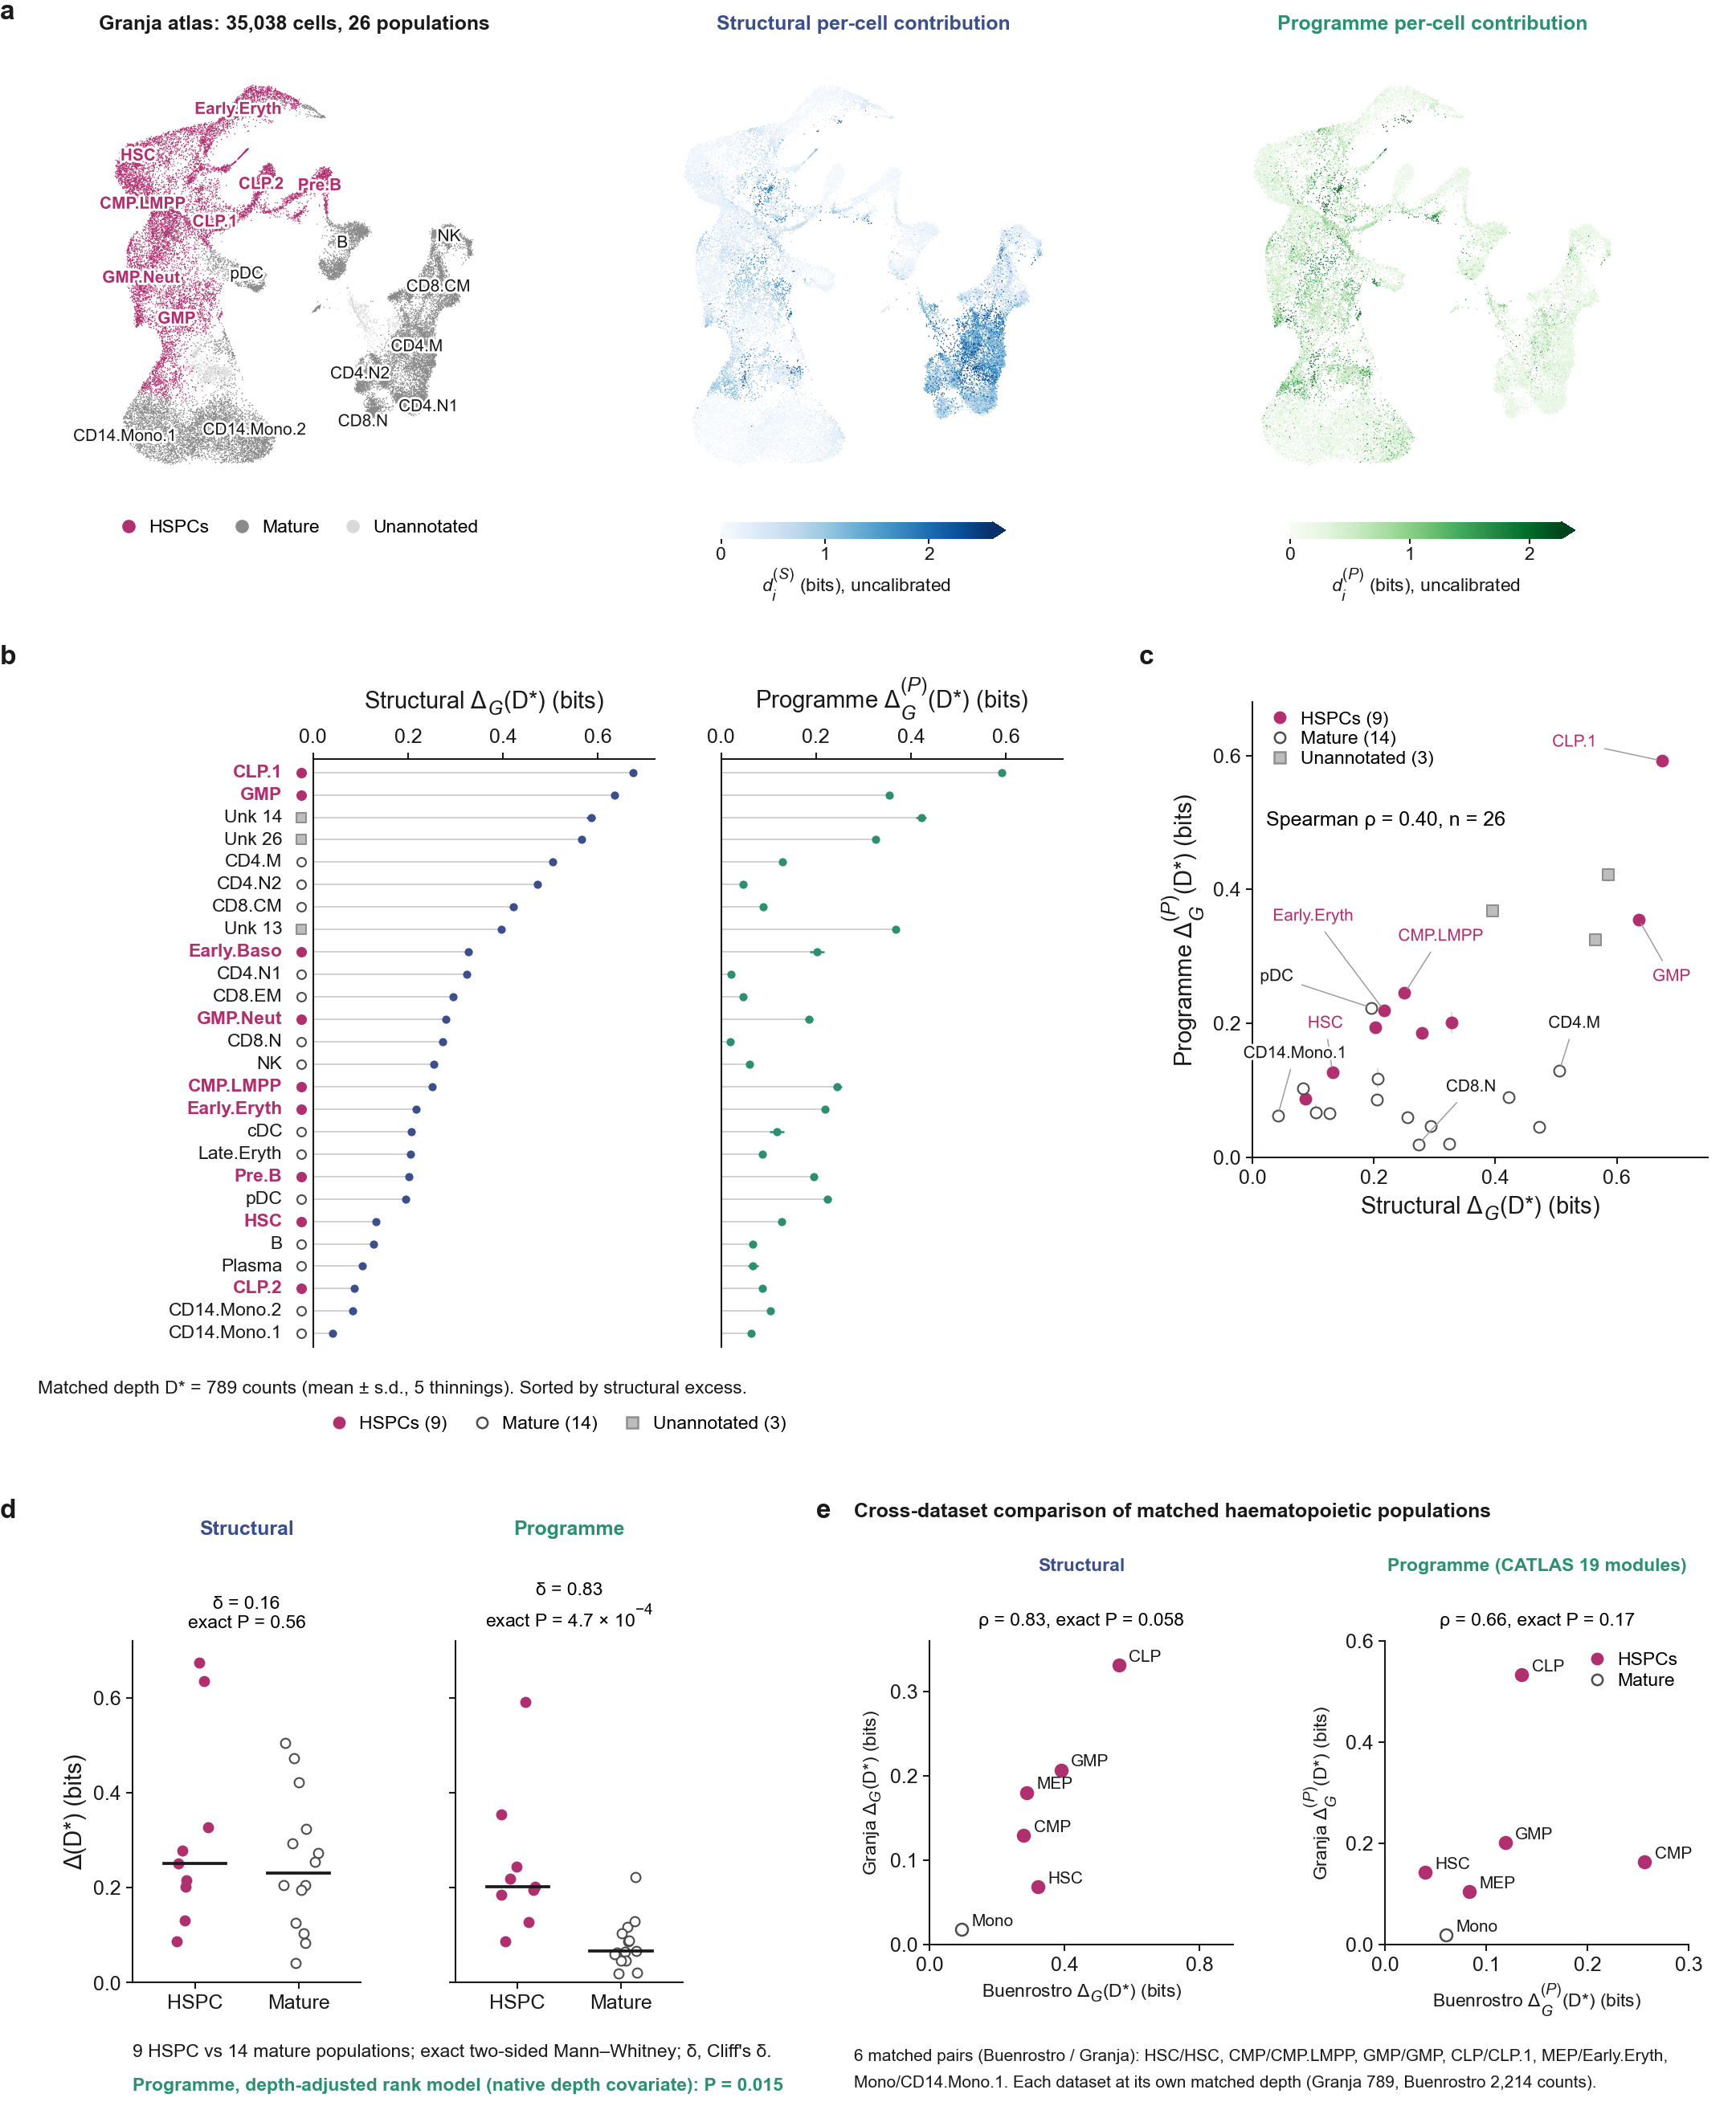

In [9]:
from IPython.display import display, Image
cv = build("Figure3", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d',PANELS['d'][0],PANELS['d'][1],panel_d),('e',PANELS['e'][0],PANELS['e'][1],panel_e)])
display(Image(filename=str(OUTPUT_DIR / "Figure3.png")))
plt.close(cv.fig)